# FaceAware AI — Dataset EDA

## Objective
Explore the facial segmentation dataset before training
or evaluating the BiSeNet model.

## Questions
1. How many images are available?
2. Do all images have corresponding masks?
3. What are the image dimensions?
4. Which segmentation classes appear in the masks?
5. Is the dataset suitable for training?

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("EDA environment is ready!")

Python version: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
NumPy version: 1.26.4
Pandas version: 3.0.6
EDA environment is ready!


In [2]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

Notebook working directory:
C:\Users\nites\Desktop\FaceAware_AI\ml\notebooks


In [3]:
DATASET_DIR = Path("../datasets")  # Change this if needed

print("Resolved dataset path:", DATASET_DIR.resolve())
print("Folder exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    for item in DATASET_DIR.iterdir():
        print(item.name, "—", "folder" if item.is_dir() else "file")

Resolved dataset path: C:\Users\nites\Desktop\FaceAware_AI\ml\datasets
Folder exists: False


## 1. Dataset paths

In this section, we define the locations of the face images
and their corresponding segmentation masks.

In [4]:
from pathlib import Path

# Replace these with the actual paths on your computer
IMAGE_DIR = Path(r"../dataset/images")
MASK_DIR = Path(r"../dataset/masks")

print("Images folder exists:", IMAGE_DIR.is_dir())
print("Masks folder exists:", MASK_DIR.is_dir())

Images folder exists: False
Masks folder exists: False


In [5]:
from pathlib import Path

# Replace these with the actual paths on your computer
IMAGE_DIR = Path(r"C:\Users\nites\Desktop\FaceAware_AI\datasets\celebAMask\images")
MASK_DIR = Path(r"C:\Users\nites\Desktop\FaceAware_AI\datasets\celebAMask\masks")

print("Images folder exists:", IMAGE_DIR.is_dir())
print("Masks folder exists:", MASK_DIR.is_dir())


Images folder exists: True
Masks folder exists: True


## 2. Dataset inventory

Count the image and mask files and inspect their filenames.

In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
MASK_EXTENSIONS = {".png"}

image_files = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

mask_files = sorted(
    p for p in MASK_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in MASK_EXTENSIONS
)

print("Number of images:", len(image_files))
print("Number of masks:", len(mask_files))

print("\nFirst 5 image filenames:")
for path in image_files[:5]:
    print(path.name)

print("\nFirst 5 mask filenames:")
for path in mask_files[:5]:
    print(path.name)
    

Number of images: 1000
Number of masks: 1000

First 5 image filenames:
00000.jpg
00001.jpg
00010.jpg
00100.jpg
00101.jpg

First 5 mask filenames:
00000.png
00001.png
00010.png
00100.png
00101.png


In [7]:
image_stems = {p.stem for p in image_files}
mask_stems = {p.stem for p in mask_files}

images_without_masks = sorted(image_stems - mask_stems)
masks_without_images = sorted(mask_stems - image_stems)

print("Images without matching masks:", len(images_without_masks))
print("Masks without matching images:", len(masks_without_images))

print("\nExamples of images without masks:")
print(images_without_masks[:10])

print("\nExamples of masks without images:")
print(masks_without_images[:10])

Images without matching masks: 0
Masks without matching images: 0

Examples of images without masks:
[]

Examples of masks without images:
[]


In [8]:
import pandas as pd

mask_by_stem = {p.stem: p for p in mask_files}

records = []

for image_path in image_files:
    mask_path = mask_by_stem.get(image_path.stem)

    records.append({
        "image_name": image_path.name,
        "image_path": str(image_path),
        "mask_name": mask_path.name if mask_path else None,
        "mask_path": str(mask_path) if mask_path else None,
        "has_mask": mask_path is not None
    })

df = pd.DataFrame(records)

display(df.head())
print("\nDataset table shape:", df.shape)
print("\nMissing masks:", df["has_mask"].eq(False).sum())

,image_name,image_path,mask_name,mask_path,has_mask
0,00000.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00000.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
1,00001.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00001.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
2,00010.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00010.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
3,00100.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00100.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
4,00101.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00101.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True



Dataset table shape: (1000, 5)

Missing masks: 0


In [9]:
from PIL import Image

image_info = []

for path in image_files:
    with Image.open(path) as img:
        image_info.append({
            "filename": path.name,
            "width": img.width,
            "height": img.height,
            "mode": img.mode,
            "format": img.format
        })

image_info_df = pd.DataFrame(image_info)

display(image_info_df.head())

print("Image dimension combinations:")
display(
    image_info_df.groupby(["width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

,filename,width,height,mode,format
0,00000.jpg,1024,1024,RGB,JPEG
1,00001.jpg,1024,1024,RGB,JPEG
2,00010.jpg,1024,1024,RGB,JPEG
3,00100.jpg,1024,1024,RGB,JPEG
4,00101.jpg,1024,1024,RGB,JPEG


Image dimension combinations:


,width,height,count
0,1024,1024,1000


In [10]:
mask_info = []

for path in mask_files:
    with Image.open(path) as mask:
        mask_info.append({
            "filename": path.name,
            "width": mask.width,
            "height": mask.height,
            "mode": mask.mode,
            "format": mask.format
        })

mask_info_df = pd.DataFrame(mask_info)

display(mask_info_df.head())

print("Masks with non-PNG format:",
      (mask_info_df["format"] != "PNG").sum())

print("Masks with dimensions different from their matching images:")

,filename,width,height,mode,format
0,00000.png,1024,1024,L,PNG
1,00001.png,1024,1024,L,PNG
2,00010.png,1024,1024,L,PNG
3,00100.png,1024,1024,L,PNG
4,00101.png,1024,1024,L,PNG


Masks with non-PNG format: 0
Masks with dimensions different from their matching images:


In [11]:
dimension_mismatches = []

for _, row in df[df["has_mask"]].iterrows():
    with Image.open(row["image_path"]) as img, \
         Image.open(row["mask_path"]) as mask:
        if img.size != mask.size:
            dimension_mismatches.append({
                "image": row["image_name"],
                "mask": row["mask_name"],
                "image_size": img.size,
                "mask_size": mask.size
            })

print("Number of dimension mismatches:", len(dimension_mismatches))
display(pd.DataFrame(dimension_mismatches).head(10))

Number of dimension mismatches: 0


""


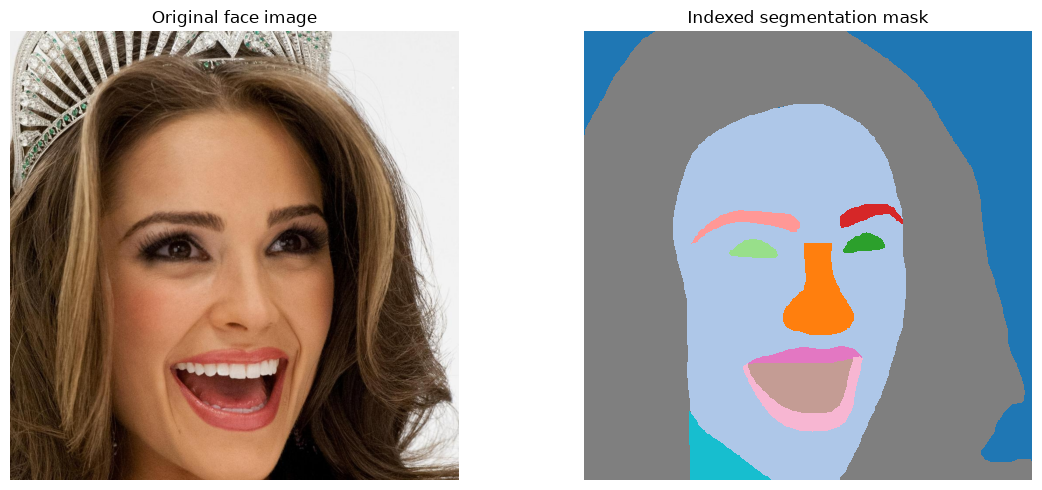

Image shape: (1024, 1024, 3)
Mask shape: (1024, 1024)
Mask data type: uint8
Unique mask values: [ 0  1  2  4  5  6  7 10 11 12 13 17]


In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Choose the first image that has a matching mask
valid_rows = df[df["has_mask"]]

if valid_rows.empty:
    print("No matching image-mask pairs found.")
else:
    sample = valid_rows.iloc[0]

    with Image.open(sample["image_path"]) as img:
        image = np.array(img.convert("RGB"))

    with Image.open(sample["mask_path"]) as mask:
        mask_array = np.array(mask)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(image)
    axes[0].set_title("Original face image")
    axes[0].axis("off")

    axes[1].imshow(mask_array, cmap="tab20", vmin=0, vmax=18,
                   interpolation="nearest")
    axes[1].set_title("Indexed segmentation mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("Image shape:", image.shape)
    print("Mask shape:", mask_array.shape)
    print("Mask data type:", mask_array.dtype)
    print("Unique mask values:", np.unique(mask_array))

In [13]:
EXPECTED_CLASSES = set(range(19))

label_counts = {}

for path in mask_files:
    with Image.open(path) as mask:
        mask_array = np.array(mask)

    if mask_array.ndim != 2:
        print("Unexpected mask shape:", path.name, mask_array.shape)
        continue

    values, counts = np.unique(mask_array, return_counts=True)

    for value, count in zip(values, counts):
        label_counts[int(value)] = (
            label_counts.get(int(value), 0) + int(count)
        )

observed_classes = set(label_counts.keys())

print("Observed class IDs:", sorted(observed_classes))
print("Missing class IDs:", sorted(EXPECTED_CLASSES - observed_classes))
print("Unexpected class IDs:", sorted(observed_classes - EXPECTED_CLASSES))

Observed class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Missing class IDs: []
Unexpected class IDs: []


## 3. Pixel-level class distribution

Calculate how many pixels belong to each segmentation class
across the complete dataset.

In [14]:
CLASS_NAMES = {
    0: "background",
    1: "skin",
    2: "nose",
    3: "eye_glasses",
    4: "left_eye",
    5: "right_eye",
    6: "left_eyebrow",
    7: "right_eyebrow",
    8: "left_ear",
    9: "right_ear",
    10: "mouth",
    11: "upper_lip",
    12: "lower_lip",
    13: "hair",
    14: "hat",
    15: "earring",
    16: "necklace",
    17: "neck",
    18: "clothing",
}

In [15]:
class_df = pd.DataFrame([
    {
        "class_id": class_id,
        "class_name": CLASS_NAMES[class_id],
        "pixel_count": label_counts.get(class_id, 0)
    }
    for class_id in range(19)
])

total_pixels = class_df["pixel_count"].sum()

class_df["pixel_percentage"] = (
    class_df["pixel_count"] / total_pixels * 100
)

display(
    class_df.sort_values("pixel_count", ascending=False)
    .reset_index(drop=True)
    .round({"pixel_percentage": 3})
)

,class_id,class_name,pixel_count,pixel_percentage
0,13,hair,336453496,32.087
1,0,background,298768224,28.493
2,1,skin,263092960,25.090
3,17,neck,41633124,3.970
4,18,clothing,33830252,3.226
5,2,nose,21397556,2.041
6,14,hat,11865440,1.132
7,12,lower_lip,7316816,0.698
8,11,upper_lip,4571160,0.436
9,8,left_ear,4502320,0.429


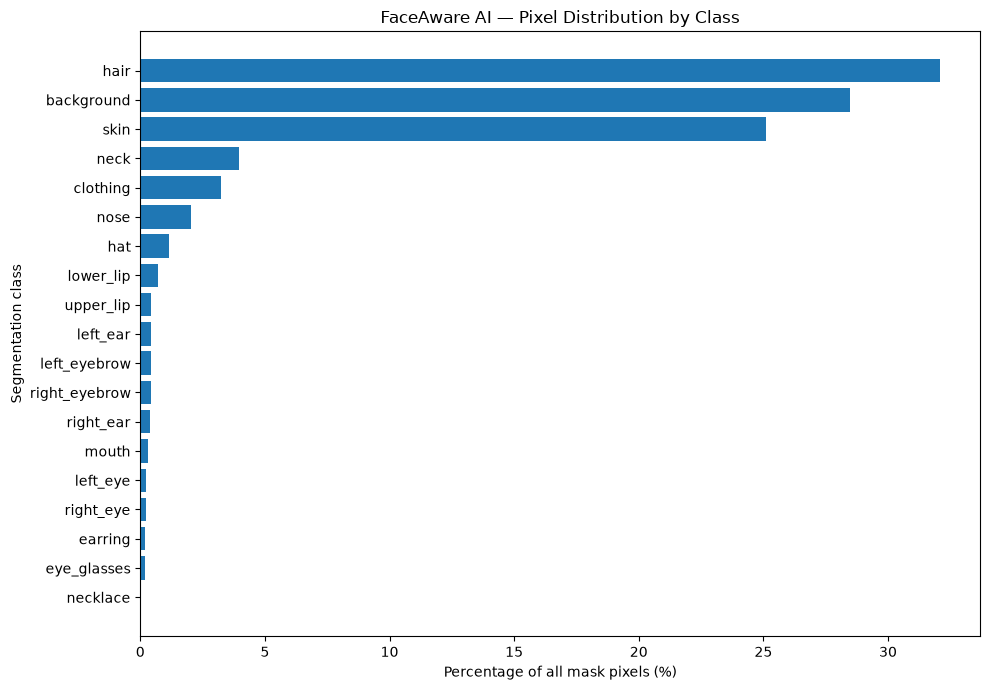

In [16]:
plot_df = class_df.sort_values("pixel_percentage")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["class_name"],
    plot_df["pixel_percentage"]
)

plt.xlabel("Percentage of all mask pixels (%)")
plt.ylabel("Segmentation class")
plt.title("FaceAware AI — Pixel Distribution by Class")
plt.tight_layout()
plt.show()

In [17]:
class_image_counts = {i: 0 for i in range(19)}

for path in mask_files:
    with Image.open(path) as mask:
        mask_array = np.array(mask)

    if mask_array.ndim != 2:
        continue

    present_classes = np.unique(mask_array)

    for class_id in present_classes:
        class_image_counts[int(class_id)] += 1

class_df["images_containing_class"] = [
    class_image_counts[class_id]
    for class_id in class_df["class_id"]
]

class_df["image_percentage"] = (
    class_df["images_containing_class"] / len(mask_files) * 100
)

display(
    class_df[
        ["class_id", "class_name", "pixel_percentage",
         "images_containing_class", "image_percentage"]
    ].round(2)
)

,class_id,class_name,pixel_percentage,images_containing_class,image_percentage
0,0,background,28.49,1000,100.0
1,1,skin,25.09,1000,100.0
2,2,nose,2.04,1000,100.0
3,3,eye_glasses,0.20,40,4.0
4,4,left_eye,0.23,979,97.9
5,5,right_eye,0.23,981,98.1
6,6,left_eyebrow,0.42,975,97.5
7,7,right_eyebrow,0.42,969,96.9
8,8,left_ear,0.43,504,50.4
9,9,right_ear,0.39,458,45.8


## 4. Preprocessing experiment

Resize one image-mask pair to 512 × 512 and check
that the mask still contains valid class IDs.

In [18]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

TARGET_SIZE = (512, 512)  # (width, height)

sample = df[df["has_mask"]].iloc[0]

# Load the original image and mask
with Image.open(sample["image_path"]) as img:
    original_image = img.convert("RGB")

with Image.open(sample["mask_path"]) as mask:
    original_mask = mask.copy()

# Resize image and mask differently
resized_image = original_image.resize(
    TARGET_SIZE,
    resample=Image.Resampling.BILINEAR
)

resized_mask = original_mask.resize(
    TARGET_SIZE,
    resample=Image.Resampling.NEAREST
)

# Convert them to NumPy arrays
image_array = np.array(resized_image)
mask_array = np.array(resized_mask)

print("Resized image shape:", image_array.shape)
print("Resized mask shape:", mask_array.shape)
print("Mask data type:", mask_array.dtype)
print("Class IDs after resizing:", np.unique(mask_array))

Resized image shape: (512, 512, 3)
Resized mask shape: (512, 512)
Mask data type: uint8
Class IDs after resizing: [ 0  1  2  4  5  6  7 10 11 12 13 17]


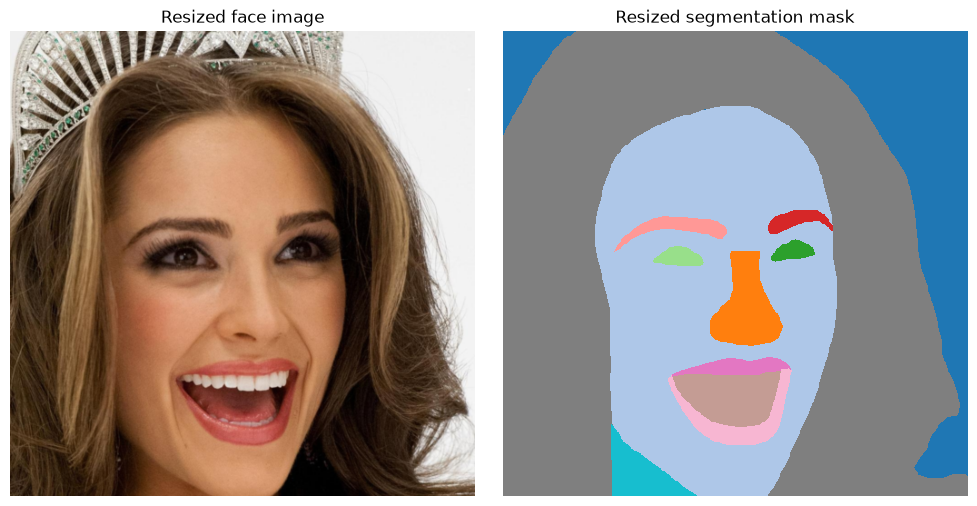

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image_array)
axes[0].set_title("Resized face image")
axes[0].axis("off")

axes[1].imshow(mask_array, cmap="tab20", vmin=0, vmax=18,
               interpolation="nearest")
axes[1].set_title("Resized segmentation mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [20]:
import torch

# Convert the image array to a PyTorch tensor
image_tensor = torch.from_numpy(image_array.copy())

# Convert uint8 pixels (0–255) to float32 pixels (0–1)
image_tensor = image_tensor.float() / 255.0

# Change layout: HWC -> CHW
image_tensor = image_tensor.permute(2, 0, 1)

# ImageNet normalization values used by your parser
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

normalized_image = (image_tensor - mean) / std

print("Original tensor layout:", image_tensor.shape)
print("Normalized tensor shape:", normalized_image.shape)
print("Tensor data type:", normalized_image.dtype)
print("Minimum normalized value:", normalized_image.min().item())
print("Maximum normalized value:", normalized_image.max().item())

Original tensor layout: torch.Size([3, 512, 512])
Normalized tensor shape: torch.Size([3, 512, 512])
Tensor data type: torch.float32
Minimum normalized value: -2.1179039478302
Maximum normalized value: 2.5702831745147705


In [21]:
mask_tensor = torch.from_numpy(mask_array.copy()).long()

print("Mask tensor shape:", mask_tensor.shape)
print("Mask tensor data type:", mask_tensor.dtype)
print("Minimum class ID:", mask_tensor.min().item())
print("Maximum class ID:", mask_tensor.max().item())
print("Unique class IDs:", torch.unique(mask_tensor))

Mask tensor shape: torch.Size([512, 512])
Mask tensor data type: torch.int64
Minimum class ID: 0
Maximum class ID: 17
Unique class IDs: tensor([ 0,  1,  2,  4,  5,  6,  7, 10, 11, 12, 13, 17])


## 5. PyTorch Dataset

Create a reusable class that loads one face image and its
corresponding segmentation mask.

In [22]:
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader
from PIL import Image


class FaceSegmentationDataset(Dataset):

    def __init__(self, dataframe, image_size=512):
        self.dataframe = dataframe[
            dataframe["has_mask"]
        ].reset_index(drop=True)

        self.image_size = image_size

        self.mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load the image
        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")
            image = image.resize(
                (self.image_size, self.image_size),
                Image.Resampling.BILINEAR
            )
            image = np.array(image)

        # Load the mask without changing its class IDs
        with Image.open(row["mask_path"]) as mask:
            mask = mask.resize(
                (self.image_size, self.image_size),
                Image.Resampling.NEAREST
            )
            mask = np.array(mask)

        if mask.ndim != 2:
            raise ValueError(
                f"Expected a 2D indexed mask, got shape {mask.shape}"
            )

        # Check that the mask contains valid class IDs
        if not np.isin(mask, np.arange(19)).all():
            raise ValueError(
                f"Invalid class IDs in {row['mask_name']}"
            )

        # Convert image to a float tensor in the range 0–1
        image_tensor = torch.from_numpy(
            image.copy()
        ).permute(2, 0, 1).float() / 255.0

        # Normalize image channels
        image_tensor = (
            image_tensor - self.mean
        ) / self.std

        # Convert mask to integer class labels
        mask_tensor = torch.from_numpy(
            mask.copy()
        ).long()

        return image_tensor, mask_tensor

In [23]:
face_dataset = FaceSegmentationDataset(
    dataframe=df,
    image_size=512
)

print("Dataset size:", len(face_dataset))

Dataset size: 1000


In [24]:
image_tensor, mask_tensor = face_dataset[0]

print("Image shape:", image_tensor.shape)
print("Mask shape:", mask_tensor.shape)
print("Image dtype:", image_tensor.dtype)
print("Mask dtype:", mask_tensor.dtype)
print("Mask class IDs:", torch.unique(mask_tensor))

Image shape: torch.Size([3, 512, 512])
Mask shape: torch.Size([512, 512])
Image dtype: torch.float32
Mask dtype: torch.int64
Mask class IDs: tensor([ 0,  1,  2,  4,  5,  6,  7, 10, 11, 12, 13, 17])


In [25]:
batch_size = 4

data_loader = DataLoader(
    face_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

images, masks = next(iter(data_loader))

print("Batch image shape:", images.shape)
print("Batch mask shape:", masks.shape)

Batch image shape: torch.Size([4, 3, 512, 512])
Batch mask shape: torch.Size([4, 512, 512])


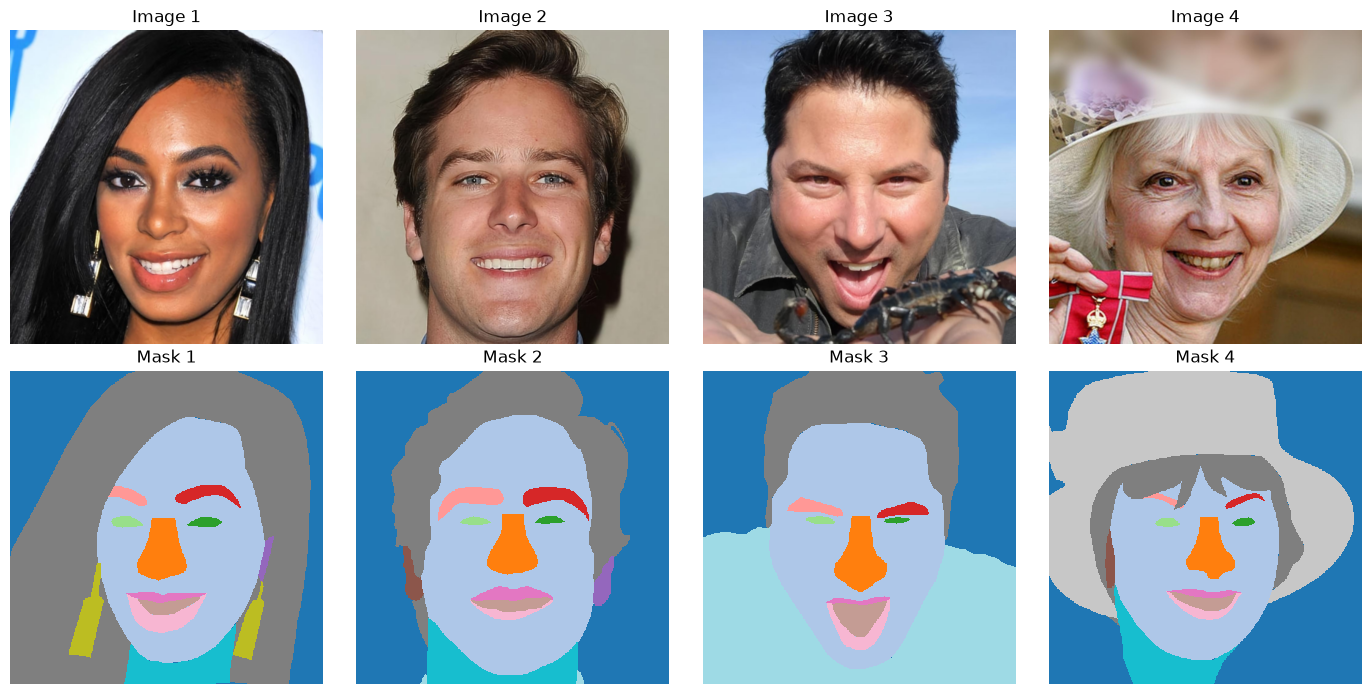

In [26]:
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):

    # Reverse normalization for visualization
    display_image = (
        images[i] * std + mean
    ).clamp(0, 1)

    display_image = display_image.permute(
        1, 2, 0
    ).numpy()

    axes[0, i].imshow(display_image)
    axes[0, i].set_title(f"Image {i + 1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        masks[i].numpy(),
        cmap="tab20",
        vmin=0,
        vmax=18,
        interpolation="nearest"
    )
    axes[1, i].set_title(f"Mask {i + 1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [27]:
from pathlib import Path

project_root = Path.cwd()

print("Current notebook directory:", project_root)

for path in project_root.rglob("parser.py"):
    print("Parser file:", path)

for path in project_root.rglob("resnet18.pt"):
    print("ResNet18 weights:", path)

for path in project_root.rglob("*bisenet*.py"):
    print("BiSeNet file:", path)

Current notebook directory: C:\Users\nites\Desktop\FaceAware_AI\ml\notebooks


In [34]:
import torch
from models.bisenet import BiSeNet

# 1. Select CPU for this initial test
device = torch.device("cpu")

# 2. Create the model with 19 output classes
model = BiSeNet(
    num_classes=19,
    backbone_name="resnet18"
)

# 3. Switch to evaluation mode
model = model.to(device)
model.eval()

# 4. Take just one image from your batch
sample_images = images[:1].to(device)

# 5. Run a forward pass without calculating gradients
with torch.no_grad():
    outputs = model(sample_images)

# 6. Inspect all three outputs
print("Number of outputs:", len(outputs))

for i, output in enumerate(outputs):
    print(
        f"Output {i}: shape={tuple(output.shape)}, "
        f"dtype={output.dtype}"
    )

Number of outputs: 3
Output 0: shape=(1, 19, 512, 512), dtype=torch.float32
Output 1: shape=(1, 19, 512, 512), dtype=torch.float32
Output 2: shape=(1, 19, 512, 512), dtype=torch.float32


In [30]:
from pathlib import Path
import os
import sys

print("Current directory:", os.getcwd())
print("\nFiles and folders here:")

for item in Path.cwd().iterdir():
    print(item.name)

print("\nPython import paths:")
print(sys.path[:5])

Current directory: C:\Users\nites\Desktop\FaceAware_AI\ml\notebooks

Files and folders here:
.ipynb_checkpoints
01_dataset_eda.ipynb

Python import paths:
['C:\\Python 312\\python312.zip', 'C:\\Python 312\\DLLs', 'C:\\Python 312\\Lib', 'C:\\Python 312', 'C:\\Users\\nites\\Desktop\\FaceAware_AI\\.venv']


In [31]:
from pathlib import Path

matches = list(Path.cwd().parent.rglob("bisenet.py"))

for path in matches:
    print(path.resolve())

C:\Users\nites\Desktop\FaceAware_AI\ml\models\bisenet.py


In [32]:
from pathlib import Path
import sys

# The notebook is in ml/notebooks, so its parent is ml
ML_DIR = Path.cwd().parent

# Add ml to Python's search paths
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

print("ML directory:", ML_DIR)
print("BiSeNet file:", ML_DIR / "models" / "bisenet.py")
print("File exists:", (ML_DIR / "models" / "bisenet.py").exists())

ML directory: C:\Users\nites\Desktop\FaceAware_AI\ml
BiSeNet file: C:\Users\nites\Desktop\FaceAware_AI\ml\models\bisenet.py
File exists: True


In [33]:
from models.bisenet import BiSeNet

print("BiSeNet imported successfully!")

BiSeNet imported successfully!


In [35]:
from pathlib import Path

# Use the ml directory we identified earlier
CHECKPOINT_PATH = (
    ML_DIR
    / "models"
    / "face_parser"
    / "training"
    / "bisenet_celebamask_best.pt"
)

print("Checkpoint path:", CHECKPOINT_PATH)
print("Checkpoint exists:", CHECKPOINT_PATH.is_file())

# List other checkpoint files in the model folder
checkpoint_dir = ML_DIR / "models" / "face_parser"

if checkpoint_dir.exists():
    for path in checkpoint_dir.rglob("*"):
        if path.is_file() and path.suffix in {".pt", ".pth", ".pth.tar"}:
            print(path)

Checkpoint path: C:\Users\nites\Desktop\FaceAware_AI\ml\models\face_parser\training\bisenet_celebamask_best.pt
Checkpoint exists: False


In [36]:
from pathlib import Path

PROJECT_ROOT = ML_DIR.parent  # FaceAware_AI

print("Project root:", PROJECT_ROOT)

for path in PROJECT_ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in {".pt", ".pth"}:
        print(path)

Project root: C:\Users\nites\Desktop\FaceAware_AI
C:\Users\nites\Desktop\FaceAware_AI\.venv\Lib\site-packages\distutils-precedence.pth
C:\Users\nites\Desktop\FaceAware_AI\face-parsing-temp\weights\resnet18.pt
C:\Users\nites\Desktop\FaceAware_AI\ml\.venv\Lib\site-packages\distutils-precedence.pth
C:\Users\nites\Desktop\FaceAware_AI\ml\venv\Lib\site-packages\distutils-precedence.pth
C:\Users\nites\Desktop\FaceAware_AI\models\face_parser\resnet18.pt
C:\Users\nites\Desktop\FaceAware_AI\models\face_parser\training\bisenet_celebamask_best.pt


In [37]:
from pathlib import Path

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "models"
    / "face_parser"
    / "training"
    / "bisenet_celebamask_best.pt"
)

print("Checkpoint path:", CHECKPOINT_PATH)
print("Checkpoint exists:", CHECKPOINT_PATH.is_file())

if CHECKPOINT_PATH.is_file():
    print(f"Checkpoint size: {CHECKPOINT_PATH.stat().st_size / (1024 * 1024):.2f} MB")

Checkpoint path: C:\Users\nites\Desktop\FaceAware_AI\models\face_parser\training\bisenet_celebamask_best.pt
Checkpoint exists: True
Checkpoint size: 52.81 MB


In [38]:
import torch

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Number of top-level entries:", len(checkpoint))
    print("First 15 keys:", list(checkpoint.keys())[:15])

Checkpoint type: <class 'collections.OrderedDict'>
Number of top-level entries: 193
First 15 keys: ['fpn.backbone.conv1.weight', 'fpn.backbone.bn1.weight', 'fpn.backbone.bn1.bias', 'fpn.backbone.bn1.running_mean', 'fpn.backbone.bn1.running_var', 'fpn.backbone.bn1.num_batches_tracked', 'fpn.backbone.layer1.0.conv1.weight', 'fpn.backbone.layer1.0.bn1.weight', 'fpn.backbone.layer1.0.bn1.bias', 'fpn.backbone.layer1.0.bn1.running_mean', 'fpn.backbone.layer1.0.bn1.running_var', 'fpn.backbone.layer1.0.bn1.num_batches_tracked', 'fpn.backbone.layer1.0.conv2.weight', 'fpn.backbone.layer1.0.bn2.weight', 'fpn.backbone.layer1.0.bn2.bias']


In [39]:
import torch
from models.bisenet import BiSeNet

# Create your current BiSeNet architecture
model = BiSeNet(
    num_classes=19,
    backbone_name="resnet18"
)

# Load the checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

# Compare checkpoint keys with model keys
model_keys = set(model.state_dict().keys())
checkpoint_keys = set(checkpoint.keys())

print("Model parameter keys:", len(model_keys))
print("Checkpoint parameter keys:", len(checkpoint_keys))

print("\nCheckpoint keys not found in model:")
print(list(checkpoint_keys - model_keys)[:15])

print("\nModel keys missing from checkpoint:")
print(list(model_keys - checkpoint_keys)[:15])

Model parameter keys: 193
Checkpoint parameter keys: 193

Checkpoint keys not found in model:
[]

Model keys missing from checkpoint:
[]


In [40]:
model_state = model.state_dict()

shape_mismatches = [
    (key, tuple(model_state[key].shape), tuple(checkpoint[key].shape))
    for key in model_state
    if model_state[key].shape != checkpoint[key].shape
]

print("Tensor shape mismatches:", len(shape_mismatches))

if shape_mismatches:
    for key, model_shape, checkpoint_shape in shape_mismatches[:10]:
        print(key, "| model:", model_shape, "| checkpoint:", checkpoint_shape)
else:
    print("All checkpoint tensor shapes match the model!")

Tensor shape mismatches: 0
All checkpoint tensor shapes match the model!


In [41]:
model.load_state_dict(checkpoint, strict=True)
model.eval()

print("BiSeNet checkpoint loaded successfully!")

BiSeNet checkpoint loaded successfully!


In [42]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Select one sample from your existing dataset
image_tensor, true_mask = dataset[0]

# Add batch dimension: [3, 512, 512] -> [1, 3, 512, 512]
input_tensor = image_tensor.unsqueeze(0)

# Run inference
model.eval()
with torch.no_grad():
    outputs = model(input_tensor)
    logits = outputs[0]
    predicted_mask = torch.argmax(logits, dim=1)[0].cpu().numpy()

# Convert ground-truth mask to NumPy
true_mask = true_mask.cpu().numpy()

# Convert normalized image back to displayable RGB
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = image_tensor.permute(1, 2, 0).cpu().numpy()
image = np.clip(image * std + mean, 0, 1)

# Visualize the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(true_mask, vmin=0, vmax=18, cmap="tab20")
axes[1].set_title("Ground-Truth Mask")

axes[2].imshow(predicted_mask, vmin=0, vmax=18, cmap="tab20")
axes[2].set_title("BiSeNet Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Predicted class IDs:", np.unique(predicted_mask))
print("Ground-truth class IDs:", np.unique(true_mask))

NameError: name 'dataset' is not defined

In [43]:
[name for name in globals() if "dataset" in name.lower()]

['DATASET_DIR', 'Dataset', 'FaceSegmentationDataset', 'face_dataset']

In [44]:
[name for name in globals() if "FaceSegmentationDataset" in name]

['FaceSegmentationDataset']

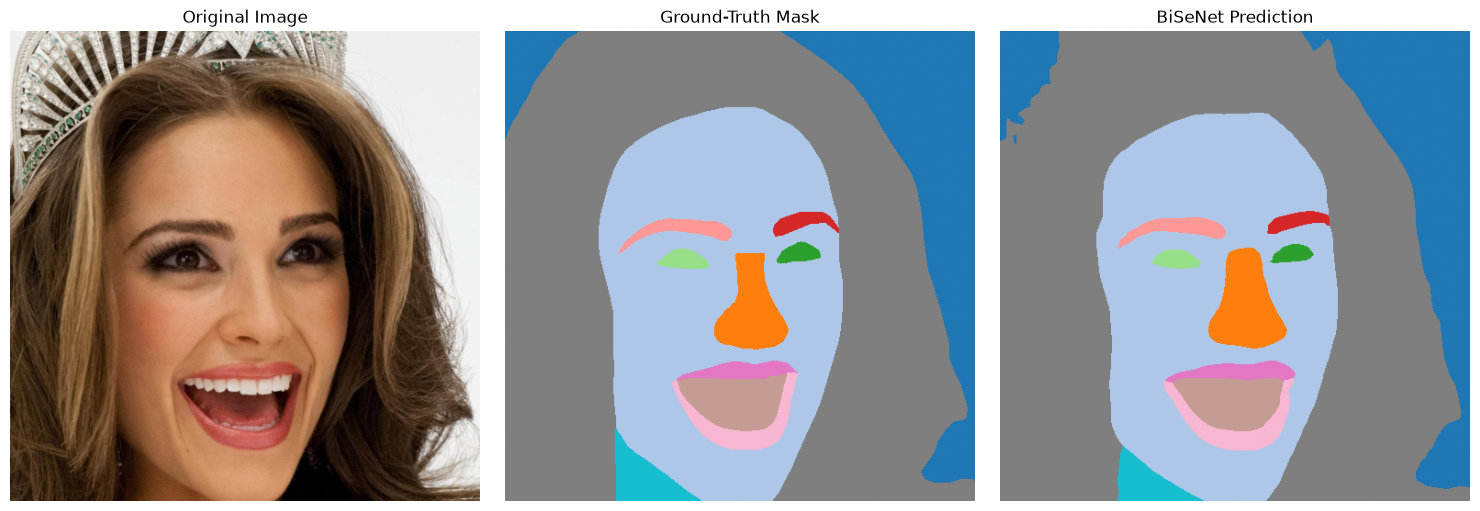

Predicted class IDs: [ 0  1  2  4  5  6  7 10 11 12 13 17]
Ground-truth class IDs: [ 0  1  2  4  5  6  7 10 11 12 13 17]


In [45]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Get one image and its ground-truth mask
image_tensor, true_mask = face_dataset[0]

# Add batch dimension
input_tensor = image_tensor.unsqueeze(0)

# Predict segmentation
model.eval()
with torch.no_grad():
    outputs = model(input_tensor)
    predicted_mask = outputs[0].argmax(dim=1)[0].cpu().numpy()

true_mask = true_mask.cpu().numpy()

# Undo ImageNet normalization for displaying the image
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = image_tensor.permute(1, 2, 0).cpu().numpy()
image = np.clip(image * std + mean, 0, 1)

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(true_mask, vmin=0, vmax=18, cmap="tab20")
axes[1].set_title("Ground-Truth Mask")

axes[2].imshow(predicted_mask, vmin=0, vmax=18, cmap="tab20")
axes[2].set_title("BiSeNet Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Predicted class IDs:", np.unique(predicted_mask))
print("Ground-truth class IDs:", np.unique(true_mask))

In [46]:
import numpy as np

# Flatten both masks into 1D arrays
y_true = true_mask.flatten()
y_pred = predicted_mask.flatten()

# Overall pixel accuracy
pixel_accuracy = np.mean(y_true == y_pred)

print(f"Pixel Accuracy: {pixel_accuracy:.4%}")

# Intersection over Union (IoU) for each class
num_classes = 19
ious = []

for class_id in range(num_classes):
    true_pixels = (y_true == class_id)
    pred_pixels = (y_pred == class_id)

    intersection = np.logical_and(true_pixels, pred_pixels).sum()
    union = np.logical_or(true_pixels, pred_pixels).sum()

    # Ignore classes absent from both masks
    if union > 0:
        iou = intersection / union
        ious.append(iou)
        print(f"Class {class_id:2d}: IoU = {iou:.4f}")

print(f"\nMean IoU (classes present in either mask): {np.mean(ious):.4f}")

Pixel Accuracy: 96.7285%
Class  0: IoU = 0.9206
Class  1: IoU = 0.9416
Class  2: IoU = 0.8204
Class  4: IoU = 0.8662
Class  5: IoU = 0.8458
Class  6: IoU = 0.8185
Class  7: IoU = 0.8380
Class 10: IoU = 0.9331
Class 11: IoU = 0.8040
Class 12: IoU = 0.7852
Class 13: IoU = 0.9580
Class 17: IoU = 0.7576

Mean IoU (classes present in either mask): 0.8574


In [47]:
print("Available dataset-related variables:")

for name in globals():
    if any(word in name.lower() for word in ["dataset", "loader", "split", "dir"]):
        value = globals()[name]
        if isinstance(value, (str, int, float, bool)):
            print(f"{name} = {value}")
        elif hasattr(value, "__len__"):
            try:
                print(f"{name}: {type(value).__name__}, length={len(value)}")
            except TypeError:
                print(f"{name}: {type(value).__name__}")

Available dataset-related variables:


RuntimeError: dictionary changed size during iteration

In [48]:
print("Available dataset-related variables:")

for name in list(globals().keys()):
    if any(word in name.lower() for word in ["dataset", "loader", "split", "dir"]):
        value = globals().get(name)

        if isinstance(value, (str, int, float, bool)):
            print(f"{name} = {value}")

        elif hasattr(value, "__len__"):
            try:
                print(f"{name}: {type(value).__name__}, length={len(value)}")
            except (TypeError, RuntimeError):
                print(f"{name}: {type(value).__name__}")

Available dataset-related variables:
DataLoader: type
FaceSegmentationDataset: type
face_dataset: FaceSegmentationDataset, length=1000
data_loader: DataLoader, length=250


In [49]:
print("Dataset root:", DATASET_DIR)
print("Dataset class:", type(face_dataset).__name__)
print("Total samples:", len(face_dataset))

print("\nDataLoader details:")
print("Batch size:", data_loader.batch_size)
print("Number of batches:", len(data_loader))

print("\nDataset object attributes:")
print(vars(face_dataset).keys())

Dataset root: ..\datasets
Dataset class: FaceSegmentationDataset
Total samples: 1000

DataLoader details:
Batch size: 4
Number of batches: 250

Dataset object attributes:
dict_keys(['dataframe', 'image_size', 'mean', 'std'])


In [50]:
from pathlib import Path

print("Dataset directory exists:", Path(DATASET_DIR).exists())

if Path(DATASET_DIR).exists():
    for path in list(Path(DATASET_DIR).iterdir())[:20]:
        print(path.name, "(directory)" if path.is_dir() else "(file)")

Dataset directory exists: False


In [51]:
print("Dataframe columns:")
print(face_dataset.dataframe.columns.tolist())

print("\nFirst five rows:")
display(face_dataset.dataframe.head())

print("\nNotebook working directory:")
print(Path.cwd())

Dataframe columns:
['image_name', 'image_path', 'mask_name', 'mask_path', 'has_mask']

First five rows:


,image_name,image_path,mask_name,mask_path,has_mask
0,00000.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00000.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
1,00001.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00001.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
2,00010.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00010.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
3,00100.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00100.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
4,00101.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00101.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True



Notebook working directory:
C:\Users\nites\Desktop\FaceAware_AI\ml\notebooks


In [52]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\nites\Desktop\FaceAware_AI")

for folder in [
    PROJECT_ROOT / "datasets",
    PROJECT_ROOT / "ml" / "datasets",
    PROJECT_ROOT / "datasets" / "celebAMask",
    PROJECT_ROOT / "ml" / "datasets" / "celebAMask",
]:
    print(f"{folder} -> exists: {folder.exists()}")

C:\Users\nites\Desktop\FaceAware_AI\datasets -> exists: True
C:\Users\nites\Desktop\FaceAware_AI\ml\datasets -> exists: False
C:\Users\nites\Desktop\FaceAware_AI\datasets\celebAMask -> exists: True
C:\Users\nites\Desktop\FaceAware_AI\ml\datasets\celebAMask -> exists: False


In [53]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\nites\Desktop\FaceAware_AI")
DATASET_ROOT = PROJECT_ROOT / "datasets" / "celebAMask"

print("Dataset root:", DATASET_ROOT)

for path in DATASET_ROOT.iterdir():
    print(
        path.name,
        "-> directory" if path.is_dir() else "-> file"
    )

    if path.is_dir():
        for child in list(path.iterdir())[:8]:
            print("   ", child.name)

Dataset root: C:\Users\nites\Desktop\FaceAware_AI\datasets\celebAMask
images -> directory
    00000.jpg
    00001.jpg
    00010.jpg
    00100.jpg
    00101.jpg
    00102.jpg
    00103.jpg
    00104.jpg
masks -> directory
    00000.png
    00001.png
    00010.png
    00100.png
    00101.png
    00102.png
    00103.png
    00104.png
mask_visualization.jpg -> file
prediction_visualization.jpg -> file
raw -> directory
    CelebA-HQ-img
    CelebAMask-HQ-mask-anno
split -> directory
    test
    train
    val


In [54]:
print("Columns:", face_dataset.dataframe.columns.tolist())
display(face_dataset.dataframe.head())

Columns: ['image_name', 'image_path', 'mask_name', 'mask_path', 'has_mask']


,image_name,image_path,mask_name,mask_path,has_mask
0,00000.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00000.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
1,00001.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00001.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
2,00010.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00010.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
3,00100.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00100.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True
4,00101.jpg,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,00101.png,C:\Users\nites\Desktop\FaceAware_AI\datasets\c...,True


In [55]:
from pathlib import Path

SPLIT_ROOT = DATASET_ROOT / "split"

for split_name in ["train", "val", "test"]:
    split_dir = SPLIT_ROOT / split_name
    print(f"\n{split_name.upper()}")

    for subfolder in ["images", "masks"]:
        folder = split_dir / subfolder
        count = len(list(folder.glob("*"))) if folder.exists() else 0
        print(f"  {subfolder}: {count} files | exists: {folder.exists()}")


TRAIN
  images: 800 files | exists: True
  masks: 800 files | exists: True

VAL
  images: 100 files | exists: True
  masks: 100 files | exists: True

TEST
  images: 100 files | exists: True
  masks: 100 files | exists: True


In [56]:
import cv2
import numpy as np
import torch
from pathlib import Path

# Use the existing project paths
VAL_ROOT = DATASET_ROOT / "split" / "val"
IMAGE_DIR = VAL_ROOT / "images"
MASK_DIR = VAL_ROOT / "masks"

IMAGE_SIZE = 512
NUM_CLASSES = 19
DEVICE = next(model.parameters()).device

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

image_paths = sorted(IMAGE_DIR.glob("*.jpg"))

assert image_paths, f"No JPG images found in {IMAGE_DIR}"

model.eval()

confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
evaluated = 0
missing_masks = []

with torch.no_grad():
    for image_path in image_paths:
        mask_path = MASK_DIR / f"{image_path.stem}.png"

        if not mask_path.exists():
            missing_masks.append(image_path.name)
            continue

        image = cv2.imread(str(image_path))
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if image is None or mask is None:
            print("Skipping unreadable file:", image_path.name)
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(
            image, (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )
        mask = cv2.resize(
            mask, (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        image = image.astype(np.float32) / 255.0
        image = (image - mean) / std
        image_tensor = torch.from_numpy(
            image.transpose(2, 0, 1)
        ).unsqueeze(0).to(DEVICE)

        output = model(image_tensor)[0]
        prediction = output.argmax(dim=1)[0].cpu().numpy()

        valid = (mask < NUM_CLASSES) & (prediction < NUM_CLASSES)
        encoded = NUM_CLASSES * mask[valid].astype(np.int64) + prediction[valid]

        confusion += np.bincount(
            encoded, minlength=NUM_CLASSES**2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

        evaluated += 1

print("Images evaluated:", evaluated)
print("Images without masks:", len(missing_masks))

if evaluated:
    pixel_accuracy = np.trace(confusion) / max(confusion.sum(), 1)

    intersection = np.diag(confusion).astype(np.float64)
    union = (
        confusion.sum(axis=1)
        + confusion.sum(axis=0)
        - intersection
    )

    class_ious = np.divide(
        intersection,
        union,
        out=np.full(NUM_CLASSES, np.nan),
        where=union > 0
    )

    print(f"\nValidation pixel accuracy: {pixel_accuracy:.4%}")
    print(f"Validation mean IoU: {np.nanmean(class_ious):.4f}")

    for class_id, iou in enumerate(class_ious):
        if not np.isnan(iou):
            print(f"Class {class_id:2d}: IoU = {iou:.4f}")

Images evaluated: 100
Images without masks: 0

Validation pixel accuracy: 93.8739%
Validation mean IoU: 0.7294
Class  0: IoU = 0.9076
Class  1: IoU = 0.9236
Class  2: IoU = 0.8726
Class  3: IoU = 0.7601
Class  4: IoU = 0.7929
Class  5: IoU = 0.7985
Class  6: IoU = 0.7429
Class  7: IoU = 0.7374
Class  8: IoU = 0.8414
Class  9: IoU = 0.7571
Class 10: IoU = 0.8258
Class 11: IoU = 0.7786
Class 12: IoU = 0.8013
Class 13: IoU = 0.8851
Class 14: IoU = 0.5487
Class 15: IoU = 0.3254
Class 16: IoU = 0.0000
Class 17: IoU = 0.8283
Class 18: IoU = 0.7318


In [57]:
import numpy as np

# 'confusion' is the matrix created during validation evaluation.
# Rows = ground-truth classes; columns = predicted classes.

class_names = [
    "background", "skin", "nose", "eyeglasses",
    "left_eye", "right_eye", "left_eyebrow", "right_eyebrow",
    "left_ear", "right_ear", "mouth", "upper_lip",
    "lower_lip", "hair", "hat", "earring",
    "necklace", "neck", "clothing"
]

ground_truth_pixels = confusion.sum(axis=1)
predicted_pixels = confusion.sum(axis=0)
correct_pixels = np.diag(confusion)

print(f"{'Class':<15} {'GT pixels':>12} {'Pred pixels':>12} {'Correct':>12}")
print("-" * 55)

for class_id, name in enumerate(class_names):
    print(
        f"{name:<15} "
        f"{ground_truth_pixels[class_id]:>12,} "
        f"{predicted_pixels[class_id]:>12,} "
        f"{correct_pixels[class_id]:>12,}"
    )

Class              GT pixels  Pred pixels      Correct
-------------------------------------------------------
background         7,425,044    7,683,064    7,188,114
skin               6,689,356    6,674,718    6,416,621
nose                 538,302      544,135      504,399
eyeglasses            26,668       33,799       26,112
left_eye              59,633       57,472       51,788
right_eye             59,665       56,860       51,734
left_eyebrow         107,386       98,136       87,604
right_eyebrow        111,767      103,506       91,368
left_ear             122,390      126,644      113,794
right_ear            114,436      119,574      100,827
mouth                 71,474       70,034       64,003
upper_lip            111,581      117,612      100,330
lower_lip            177,031      192,242      164,273
hair               8,412,326    8,267,585    7,831,396
hat                  232,908      278,716      181,266
earring               52,917       30,809       20,557
necklace 

In [58]:
import numpy as np

class_names = [
    "background", "skin", "nose", "eyeglasses",
    "left_eye", "right_eye", "left_eyebrow", "right_eyebrow",
    "left_ear", "right_ear", "mouth", "upper_lip",
    "lower_lip", "hair", "hat", "earring",
    "necklace", "neck", "clothing"
]

necklace_id = 16

print("Ground-truth necklace pixels predicted as:")
print()

row = confusion[necklace_id]
total = row.sum()

for class_id, count in enumerate(row):
    if count > 0:
        print(
            f"{class_names[class_id]:<15}: "
            f"{count:>7,} pixels ({count / total * 100:.2f}%)"
        )

Ground-truth necklace pixels predicted as:

background     :     137 pixels (3.85%)
hair           :   1,228 pixels (34.54%)
earring        :     188 pixels (5.29%)
neck           :   1,668 pixels (46.92%)
clothing       :     334 pixels (9.40%)


In [59]:
from pathlib import Path
import cv2
import numpy as np

TRAIN_MASK_DIR = DATASET_ROOT / "split" / "train" / "masks"
NUM_CLASSES = 19

pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
mask_paths = sorted(TRAIN_MASK_DIR.glob("*.png"))

for mask_path in mask_paths:
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        continue

    counts = np.bincount(mask.ravel(), minlength=NUM_CLASSES)
    pixel_counts += counts[:NUM_CLASSES]

total_pixels = pixel_counts.sum()

print("Training masks:", len(mask_paths))
print(f"{'Class':<12} {'Pixels':>12} {'Percentage':>12}")
print("-" * 38)

for class_id, count in enumerate(pixel_counts):
    print(
        f"{class_id:<12} {count:>12,} "
        f"{100 * count / total_pixels:>11.5f}%"
    )

print(
    "\nNecklace pixel percentage:",
    f"{100 * pixel_counts[16] / total_pixels:.5f}%"
)

Training masks: 800
Class              Pixels   Percentage
--------------------------------------
0             238,336,324    28.41190%
1             209,800,680    25.01019%
2              17,164,672     2.04619%
3               1,786,700     0.21299%
4               1,895,764     0.22599%
5               1,899,304     0.22641%
6               3,575,784     0.42627%
7               3,496,272     0.41679%
8               3,578,232     0.42656%
9               3,148,032     0.37527%
10              2,525,488     0.30106%
11              3,672,844     0.43784%
12              5,890,712     0.70223%
13            269,132,276    32.08307%
14             10,188,396     1.21455%
15              1,775,036     0.21160%
16                128,880     0.01536%
17             32,847,328     3.91571%
18             28,018,076     3.34001%

Necklace pixel percentage: 0.01536%


In [60]:
from pathlib import Path
import cv2
import numpy as np

mask_dir = DATASET_ROOT / "split" / "train" / "masks"

necklace_images = 0
total_images = 0

for mask_path in mask_dir.glob("*.png"):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        continue

    total_images += 1

    if np.any(mask == 16):
        necklace_images += 1

print("Total training images:", total_images)
print("Images containing necklaces:", necklace_images)
print(
    "Percentage:",
    round(necklace_images / total_images * 100, 2),
    "%"
)

Total training images: 800
Images containing necklaces: 43
Percentage: 5.38 %
